In [5]:
#Student Performance Prediction by using classification(UCI Machine Learning Repository -student-mat.csv)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score,confusion_matrix,classification_report,ConfusionMatrixDisplay
print("Student Performance Classification")

Student Performance Classification


In [6]:
# 1. Load Dataset
data = pd.read_csv("student-mat.csv", sep=";")
print("Dataset loaded successfully")
print("Dataset shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("\nFirst 5 rows:")
print(data.head())

Dataset loaded successfully
Dataset shape: (395, 33)
Missing values: 0

First 5 rows:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]


In [7]:
# 2. Convert Gender into Numbers
# Male = 1, Female = 0
data["sex"] = data["sex"].map({
    "M": 1,
    "F": 0
})

In [8]:
# 3. Create Classification Target
# G3 >= 10 --> Pass = 1
# G3 < 10  --> Fail = 0
data["result"] = (data["G3"] >= 10).astype(int)
print("\nClassification Target:")
print(data["result"].value_counts())
print("\n0 = Fail")
print("1 = Pass")


Classification Target:
result
1    265
0    130
Name: count, dtype: int64

0 = Fail
1 = Pass


In [9]:
# 4. Select Features
features = [
    "sex",
    "age",
    "studytime",
    "absences",
    "failures",
    "G1",
    "G2"
]
X = data[features]
y = data["result"]
print("\nInput Features:")
print(features)
print("\nTarget: Pass/Fail")


Input Features:
['sex', 'age', 'studytime', 'absences', 'failures', 'G1', 'G2']

Target: Pass/Fail


In [10]:
# 4. Select Features
features = [
    "sex",
    "age",
    "studytime",
    "absences",
    "failures",
    "G1",
    "G2"
]
X = data[features]
y = data["result"]
print("\nInput Features:")
print(features)
print("\nTarget: Pass/Fail")


Input Features:
['sex', 'age', 'studytime', 'absences', 'failures', 'G1', 'G2']

Target: Pass/Fail


In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
# 6. Create Classification Model
model = LogisticRegression(max_iter=1000)
# Train model
model.fit(X_train, y_train)
print("\nLogistic Regression model trained successfully!")

Training data: (316, 7)
Testing data: (79, 7)

Logistic Regression model trained successfully!


In [12]:
# 7. Make Predictions
y_pred = model.predict(X_test)
print("\nActual Results:")
print(y_test.values[:10])
print("\nPredicted Results:")
print(y_pred[:10])


Actual Results:
[1 1 0 1 0 1 1 0 0 1]

Predicted Results:
[0 1 0 0 0 1 1 0 0 1]


In [13]:
# 8. Prediction Probabilities
y_probability = model.predict_proba(X_test)
print("\nPrediction Probabilities:")
print(np.round(y_probability[:10], 2))


Prediction Probabilities:
[[0.84 0.16]
 [0.   1.  ]
 [1.   0.  ]
 [0.56 0.44]
 [0.89 0.11]
 [0.   1.  ]
 [0.   1.  ]
 [0.97 0.03]
 [0.95 0.05]
 [0.   1.  ]]


In [14]:
# 9. Model Evaluation
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("\nModel Evaluation")
print("----------------")
print("Accuracy :", round(accuracy, 2))
print("Precision:", round(precision, 2))
print("Recall   :", round(recall, 2))
print("F1 Score :", round(f1, 2))


Model Evaluation
----------------
Accuracy : 0.9
Precision: 0.94
Recall   : 0.9
F1 Score : 0.92


In [15]:
# 10. Classification Report
print("\nClassification Report")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fail", "Pass"]
    )
)


Classification Report
---------------------
              precision    recall  f1-score   support

        Fail       0.83      0.89      0.86        27
        Pass       0.94      0.90      0.92        52

    accuracy                           0.90        79
   macro avg       0.88      0.90      0.89        79
weighted avg       0.90      0.90      0.90        79



In [16]:
# 11. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)



Confusion Matrix:
[[24  3]
 [ 5 47]]


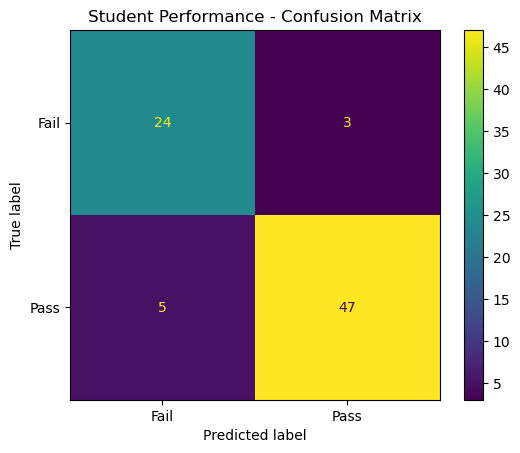

In [17]:
# 12. Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)
disp.plot()
plt.title("Student Performance - Confusion Matrix")
plt.show()

In [18]:
# 13. Predict a New Student
print("\nEnter New Student Details")
name = input("Name: ")
sex_input = input("Gender (M/F): ")
age = float(input("Age: "))
studytime = float(input("Study time (1-4): "))
absences = float(input("Absences: "))
failures = float(input("Previous failures: "))
g1 = float(input("G1 (First period grade 0-20): "))
g2 = float(input("G2 (Second period grade 0-20): "))


Enter New Student Details


Name:  vasu
Gender (M/F):  F
Age:  19
Study time (1-4):  4
Absences:  0
Previous failures:  0
G1 (First period grade 0-20):  17
G2 (Second period grade 0-20):  16


In [19]:
# 14. Convert Gender
sex = 1 if sex_input.upper() == "M" else 0
# 15. Create New Student DataFrame
student = pd.DataFrame({
    "sex": [sex],
    "age": [age],
    "studytime": [studytime],
    "absences": [absences],
    "failures": [failures],
    "G1": [g1],
    "G2": [g2]
})
print("\nStudent Details:")
print(student)


Student Details:
   sex   age  studytime  absences  failures    G1    G2
0    0  19.0        4.0       0.0       0.0  17.0  16.0


In [20]:
# 16. Predict Pass/Fail
prediction = model.predict(student)[0]
probability = model.predict_proba(student)[0]
pass_probability = probability[1]
fail_probability = probability[0]

In [21]:
# 17. Display Prediction
print("\nPrediction Result")
print("-----------------")
print("Name:", name)
print("Gender:", "Male" if sex == 1 else "Female")
print("Age:", age)
print("Study Time:", studytime)
print("Absences:", absences)
print("Previous Failures:", failures)
print("G1:", g1)
print("G2:", g2)
if prediction == 1:
    print("Predicted Result: PASS")
else:
    print("Predicted Result: FAIL")



Prediction Result
-----------------
Name: vasu
Gender: Female
Age: 19.0
Study Time: 4.0
Absences: 0.0
Previous Failures: 0.0
G1: 17.0
G2: 16.0
Predicted Result: PASS
